# 03c — Dual-Head ViT Comparison Hub (StreetCLIP vs. SigLIP 2)

This notebook aggregates and compares the **4 trained dual-head ViT models** produced by:
- `notebooks/04a_streetclip.ipynb` → `streetclip_linear_probe`, `streetclip_finetune`
- `notebooks/04b_siglip2.ipynb` → `siglip2_linear_probe`, `siglip2_finetune`

All metrics are evaluated on the **1,600 strictly held-out Timeguessr daily challenge photos** using the exact formulas in `formulas.txt`.

## 1. Load Standardized Outputs from All 4 Runs

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"

RUN_SPECS = [
    ("streetclip_linear_probe", "StreetCLIP — Linear Probe"),
    ("streetclip_linear_probe_tuned", "StreetCLIP — Linear Probe (Tuned)"),
    ("streetclip_finetune", "StreetCLIP — Fine-Tune (Last 6)"),
    # ("siglip2_linear_probe", "SigLIP 2 — Linear Probe"),
    # ("siglip2_finetune", "SigLIP 2 — Fine-Tune (Last 6)"),
]

runs = {}
for folder, label in RUN_SPECS:
    run_dir = MODELS_DIR / folder
    metrics_path = run_dir / "metrics.json"
    preds_path = run_dir / "test_predictions.csv"
    if not metrics_path.exists() or not preds_path.exists():
        print(f"[MISSING] {label:32s} -> {run_dir}")
        continue
    with open(metrics_path, encoding="utf-8") as f:
        meta = json.load(f)
    runs[label] = {
        "folder": folder,
        "meta": meta,
        "preds": pd.read_csv(preds_path, keep_default_na=False),
    }
    print(f"[LOADED]  {label:32s} | test total mean = {meta['test_timeguessr_metrics']['total_score_mean']:.1f}")

assert len(runs) > 0, "No completed runs found yet. Run 04a_streetclip.ipynb and/or 04b_siglip2.ipynb first."

[LOADED]  StreetCLIP — Linear Probe        | test total mean = 7616.6
[LOADED]  StreetCLIP — Linear Probe (Tuned) | test total mean = 7688.4
[LOADED]  StreetCLIP — Fine-Tune (Last 6)  | test total mean = 7684.6


## 2. 4-Way Held-Out Timeguessr Benchmark Table

In [11]:
summary_rows = []
for label, data in runs.items():
    m = data["meta"]["test_timeguessr_metrics"]
    summary_rows.append({
        "Model": label,
        "Total Mean (/10k)": m["total_score_mean"],
        "Total Median": m["total_score_median"],
        "Loc Mean (/5k)": m["loc_score_mean"],
        "Loc Top-k Mean": m.get("loc_score_mean_topk", np.nan),
        "Year Mean (/5k)": m["year_score_mean"],
        "Med Dist (km)": m["dist_err_median_km"],
        "<=200km (%)": m["within_200km_pct"],
        "<=750km (%)": m["within_750km_pct"],
        "Country Acc (%)": m.get("country_acc_pct", np.nan),
        "Year MAE": m["year_mae"],
        "<=15yr (%)": m["year_within_15_pct"],
    })

summary_df = pd.DataFrame(summary_rows).set_index("Model")
display(summary_df.sort_values("Total Mean (/10k)", ascending=False))

,Total Mean (/10k),Total Median,Loc Mean (/5k),Loc Top-k Mean,Year Mean (/5k),Med Dist (km),<=200km (%),<=750km (%),Country Acc (%),Year MAE,<=15yr (%)
Model,,,,,,,,,,,
StreetCLIP — Linear Probe (Tuned),7688.41,8145.73,3504.63,3504.63,4183.78,371.05,28.06,70.94,44.31,5.05,95.19
StreetCLIP — Fine-Tune (Last 6),7684.62,8167.54,3457.40,3457.40,4227.22,364.99,28.88,68.81,43.31,4.82,96.38
StreetCLIP — Linear Probe,7616.56,8099.86,3444.98,3444.98,4171.58,376.89,28.62,68.19,44.06,5.20,95.06


## 2b. Location Error Decomposition: Discretization vs. Model Misclassification

Separates each model's total location score loss (`5000 - Model Loc Score`) into:
1. **Discretization (Quantization) Loss (`5000 - Oracle Score`):** Irreducible error from snapping each photo's true `(lat, lon)` to its ground-truth tile centroid.
2. **Model Misclassification Loss (`Oracle Score - Model Loc Score`):** Additional error caused by predicting the wrong tile class.

Also reports **Exact Tile Top-1 / Top-5 Accuracy**, **Right Country / Wrong Tile %**, **Median Distance on Exact Tile Hits**, and **Median Inter-Tile Centroid Distance**.

Oracle Discretization Ceiling (semantic_medium, 841 tiles): mean_loc=4851.6/5000 | disc_loss=148.4 pts | med_dist=9.5 km | mean_dist=29.7 km


,Total Loc Loss (pts),Discretization Loss (pts),Misclassification Loss (pts),Discretization Share (%),Misclassification Share (%),Exact Tile Top-1 (%),Exact Tile Top-5 (%),Right Country / Wrong Tile (%),Med Dist on Tile Hits (km),Med Inter-Tile Dist (km)
Model,,,,,,,,,,
StreetCLIP — Linear Probe,1555.0,148.4,1406.6,9.5,90.5,7.19,29.12,37.4,163.1,374.1
StreetCLIP — Linear Probe (Tuned),1495.4,148.4,1346.9,9.9,90.1,7.12,31.19,37.2,150.0,371.4
StreetCLIP — Fine-Tune (Last 6),1542.6,148.4,1394.2,9.6,90.4,6.75,28.75,36.8,154.3,359.0


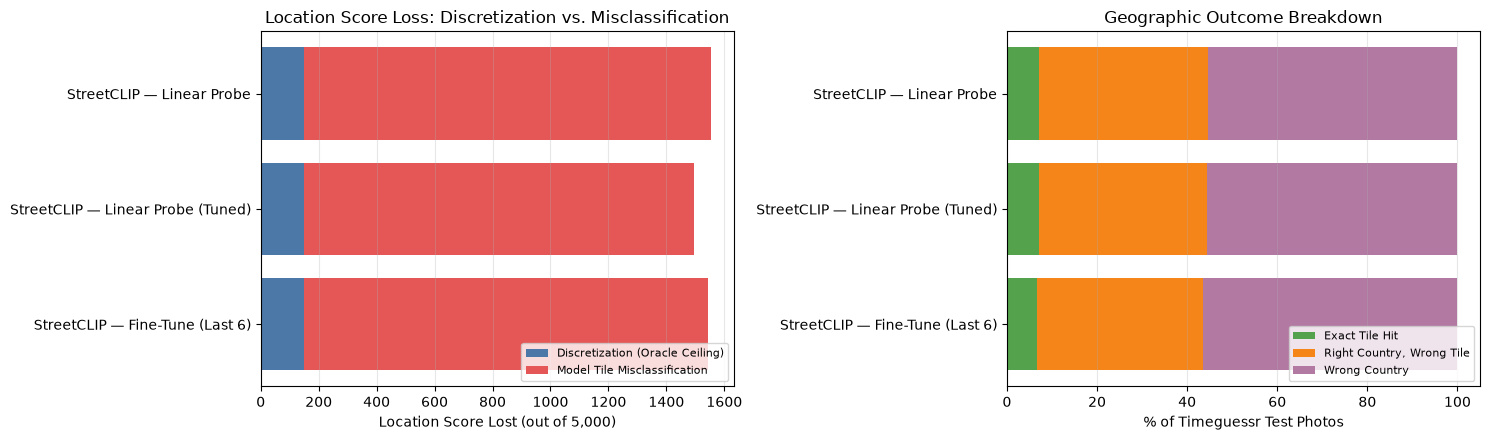

In [12]:
import sys
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from timeguessr_ai import haversine_km, load_dataset_and_tiles, timeguessr_location_score

first_cfg = next(iter(runs.values()))["meta"]["config"]
tile_scheme = first_cfg.get("tile_scheme", "semantic_medium")
splits, cells_df, _ = load_dataset_and_tiles(PROJECT_ROOT, tile_scheme=tile_scheme)
test_df = splits["test_timeguessr"]

tile_lookup = cells_df.set_index("tile_id")
true_tid = test_df["tile_id"].to_numpy()
oracle_lat = tile_lookup.loc[true_tid, "centroid_lat"].to_numpy()
oracle_lon = tile_lookup.loc[true_tid, "centroid_lon"].to_numpy()

oracle_dist_km = haversine_km(
    test_df["latitude"].to_numpy(), test_df["longitude"].to_numpy(), oracle_lat, oracle_lon
)
oracle_loc_score = timeguessr_location_score(oracle_dist_km)
oracle_mean_score = float(oracle_loc_score.mean())
disc_score_loss = 5000.0 - oracle_mean_score

print(
    f"Oracle Discretization Ceiling ({tile_scheme}, {len(cells_df):,} tiles): "
    f"mean_loc={oracle_mean_score:.1f}/5000 | disc_loss={disc_score_loss:.1f} pts | "
    f"med_dist={np.median(oracle_dist_km):.1f} km | mean_dist={oracle_dist_km.mean():.1f} km"
)

decomp_rows = []
for label, data in runs.items():
    p = data["preds"]
    pred_tid = p["pred_tile_id"].to_numpy()
    hit_mask = pred_tid == true_tid
    same_cc = p["pred_country"].to_numpy() == p["true_country"].to_numpy()
    wrong_tile_same_cc = same_cc & (~hit_mask)

    logits_path = MODELS_DIR / data["folder"] / "test_space_logits.npy"
    if logits_path.exists():
        logits = np.load(logits_path)
        top5_idx = np.argsort(-logits, axis=1)[:, :5]
        top5_acc = float(np.any(top5_idx == true_tid[:, None], axis=1).mean() * 100.0)
    else:
        top5_acc = np.nan

    model_loc_mean = float(p["loc_score"].mean())
    total_loc_loss = 5000.0 - model_loc_mean
    cls_score_loss = max(oracle_mean_score - model_loc_mean, 0.0)
    disc_share_pct = (disc_score_loss / max(total_loc_loss, 1e-6)) * 100.0
    cls_share_pct = 100.0 - disc_share_pct

    inter_tile_km = haversine_km(oracle_lat, oracle_lon, p["pred_lat"].to_numpy(), p["pred_lon"].to_numpy())
    hit_med_km = float(np.median(p.loc[hit_mask, "dist_km"])) if hit_mask.any() else np.nan

    decomp_rows.append({
        "Model": label,
        "Total Loc Loss (pts)": round(total_loc_loss, 1),
        "Discretization Loss (pts)": round(disc_score_loss, 1),
        "Misclassification Loss (pts)": round(cls_score_loss, 1),
        "Discretization Share (%)": round(disc_share_pct, 1),
        "Misclassification Share (%)": round(cls_share_pct, 1),
        "Exact Tile Top-1 (%)": round(float(hit_mask.mean() * 100.0), 2),
        "Exact Tile Top-5 (%)": round(top5_acc, 2),
        "Right Country / Wrong Tile (%)": round(float(wrong_tile_same_cc.mean() * 100.0), 1),
        "Med Dist on Tile Hits (km)": round(hit_med_km, 1),
        "Med Inter-Tile Dist (km)": round(float(np.median(inter_tile_km)), 1),
    })

decomp_df = pd.DataFrame(decomp_rows).set_index("Model")
display(decomp_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# (A) Stacked horizontal bar: Discretization vs Misclassification score loss
y_pos = np.arange(len(decomp_df))
axes[0].barh(y_pos, decomp_df["Discretization Loss (pts)"], label="Discretization (Oracle Ceiling)", color="#4C78A8")
axes[0].barh(
    y_pos,
    decomp_df["Misclassification Loss (pts)"],
    left=decomp_df["Discretization Loss (pts)"],
    label="Model Tile Misclassification",
    color="#E45756",
)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(decomp_df.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("Location Score Lost (out of 5,000)")
axes[0].set_title("Location Score Loss: Discretization vs. Misclassification")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(axis="x", alpha=0.3)

# (B) Geographic prediction accuracy breakdown
exact_pct = decomp_df["Exact Tile Top-1 (%)"].to_numpy()
same_cc_wrong_tile = decomp_df["Right Country / Wrong Tile (%)"].to_numpy()
wrong_cc_pct = 100.0 - exact_pct - same_cc_wrong_tile
axes[1].barh(y_pos, exact_pct, label="Exact Tile Hit", color="#54A24B")
axes[1].barh(y_pos, same_cc_wrong_tile, left=exact_pct, label="Right Country, Wrong Tile", color="#F58518")
axes[1].barh(y_pos, wrong_cc_pct, left=exact_pct + same_cc_wrong_tile, label="Wrong Country", color="#B279A2")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(decomp_df.index)
axes[1].invert_yaxis()
axes[1].set_xlabel("% of Timeguessr Test Photos")
axes[1].set_title("Geographic Outcome Breakdown")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Score Comparison & Error CDFs (Location & Year)

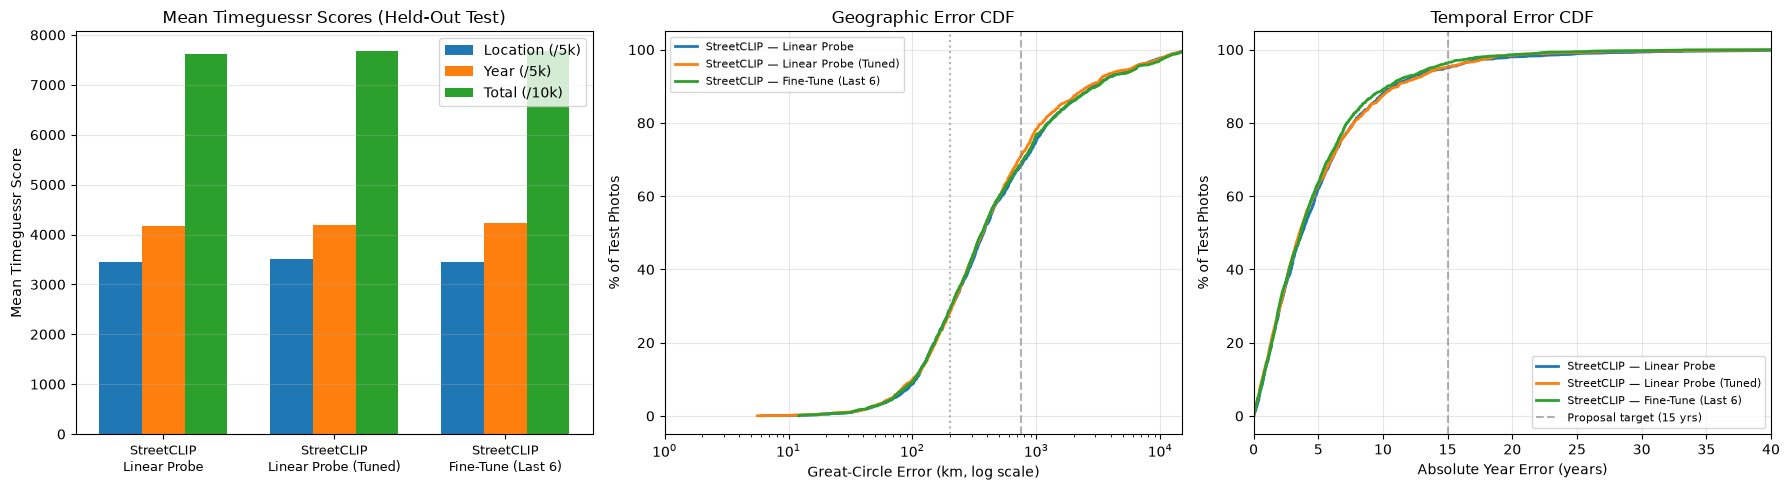

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (A) Grouped Bar Chart: Location, Year, and Total Score
labels = list(runs.keys())
x = np.arange(len(labels))
width = 0.25
loc_scores = [runs[l]["meta"]["test_timeguessr_metrics"]["loc_score_mean"] for l in labels]
yr_scores = [runs[l]["meta"]["test_timeguessr_metrics"]["year_score_mean"] for l in labels]
tot_scores = [runs[l]["meta"]["test_timeguessr_metrics"]["total_score_mean"] for l in labels]

axes[0].bar(x - width, loc_scores, width, label="Location (/5k)")
axes[0].bar(x, yr_scores, width, label="Year (/5k)")
axes[0].bar(x + width, tot_scores, width, label="Total (/10k)")
axes[0].set_xticks(x)
axes[0].set_xticklabels([l.replace(" — ", "\n") for l in labels], fontsize=9)
axes[0].set_ylabel("Mean Timeguessr Score")
axes[0].set_title("Mean Timeguessr Scores (Held-Out Test)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# (B) Distance Error CDF
for label, data in runs.items():
    d = np.sort(data["preds"]["dist_km"].to_numpy())
    cdf = np.arange(1, len(d) + 1) / len(d) * 100.0
    axes[1].plot(d, cdf, linewidth=2, label=label)
axes[1].set_xscale("log")
axes[1].set_xlim(1, 15000)
axes[1].axvline(200, color="gray", linestyle=":", alpha=0.6)
axes[1].axvline(750, color="gray", linestyle="--", alpha=0.6)
axes[1].set_xlabel("Great-Circle Error (km, log scale)")
axes[1].set_ylabel("% of Test Photos")
axes[1].set_title("Geographic Error CDF")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# (C) Year Error CDF
for label, data in runs.items():
    ye = np.sort(data["preds"]["year_err"].to_numpy())
    cdf = np.arange(1, len(ye) + 1) / len(ye) * 100.0
    axes[2].plot(ye, cdf, linewidth=2, label=label)
axes[2].set_xlim(0, 40)
axes[2].axvline(15, color="gray", linestyle="--", alpha=0.6, label="Proposal target (15 yrs)")
axes[2].set_xlabel("Absolute Year Error (years)")
axes[2].set_ylabel("% of Test Photos")
axes[2].set_title("Temporal Error CDF")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Breakdown by Decade & Top Countries

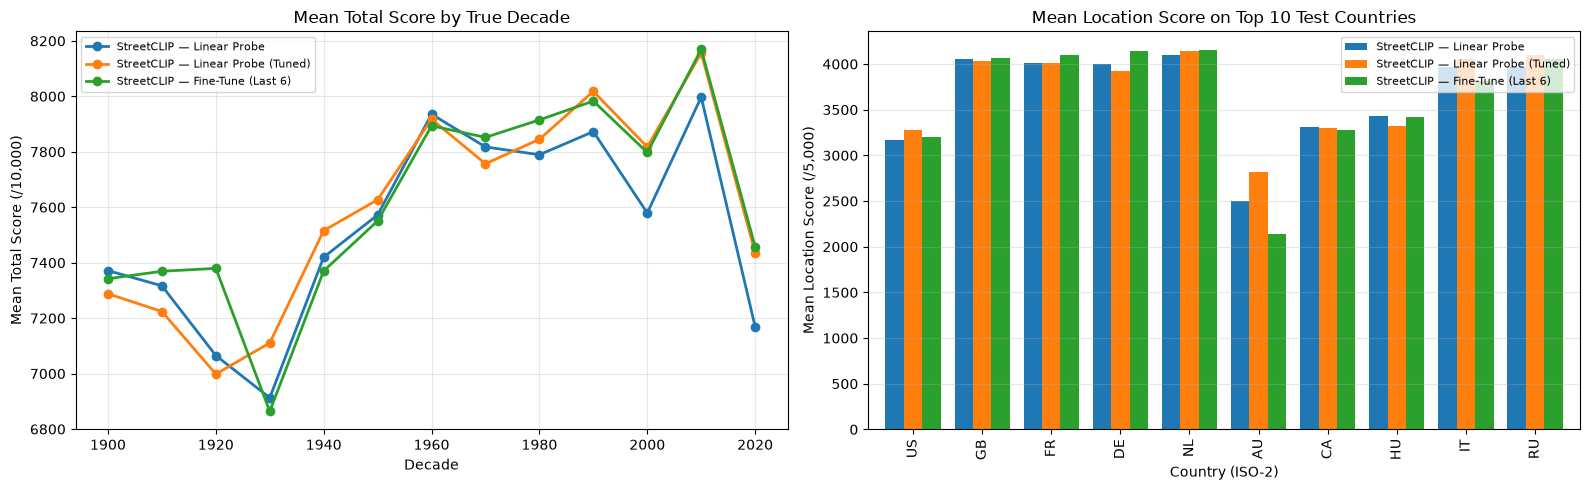

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Decade breakdown (mean total score)
for label, data in runs.items():
    df_p = data["preds"].copy()
    df_p["decade"] = (df_p["true_year"] // 10) * 10
    by_dec = df_p.groupby("decade")["total_score"].mean()
    axes[0].plot(by_dec.index, by_dec.values, marker="o", linewidth=2, label=label)
axes[0].set_title("Mean Total Score by True Decade")
axes[0].set_xlabel("Decade")
axes[0].set_ylabel("Mean Total Score (/10,000)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

# Top 10 countries in Timeguessr test set (mean location score)
first_preds = next(iter(runs.values()))["preds"]
top_countries = first_preds["true_country"].value_counts().head(10).index.tolist()
country_scores = pd.DataFrame(
    {
        label: data["preds"][data["preds"]["true_country"].isin(top_countries)]
        .groupby("true_country")["loc_score"]
        .mean()
        .reindex(top_countries)
        for label, data in runs.items()
    }
)
country_scores.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("Mean Location Score on Top 10 Test Countries")
axes[1].set_xlabel("Country (ISO-2)")
axes[1].set_ylabel("Mean Location Score (/5,000)")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()